<a href="https://colab.research.google.com/github/Rytham00/sleep-caffeine-tracker/blob/main/tracker.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("tracker.csv")
df.columns = df.columns.str.strip().str.lower()   # tidy column names
df["date"] = pd.to_datetime(df["date"], format="%d.%m.%y")

print(df.head())
print(df.dtypes)
print("Dates:", df["date"].min(), "to", df["date"].max())
print("Missing values:\n", df.isna().sum())

        date  caffeine_mg  sleep_hours  exam_season wake_time
0 2026-09-01         42.0          9.5          0.0       NaN
1 2026-09-02        102.0          8.5          0.0       NaN
2 2026-09-03         95.0          8.5          0.0       NaN
3 2026-09-04         84.0          6.0          0.0       NaN
4 2026-09-05         80.0         11.0          0.0       NaN
date           datetime64[ns]
caffeine_mg           float64
sleep_hours           float64
exam_season           float64
wake_time              object
dtype: object
Dates: 2026-09-01 00:00:00 to 2026-10-12 00:00:00
Missing values:
 date            0
caffeine_mg     3
sleep_hours     6
exam_season     1
wake_time      29
dtype: int64


In [9]:
df = df.dropna(subset=["sleep_hours", "caffeine_mg"])
print(len(df), "usable days")
df[["caffeine_mg", "sleep_hours"]].describe()

36 usable days


,caffeine_mg,sleep_hours
count,36.000000,36.000000
mean,58.055556,7.625000
std,30.493038,2.911492
min,0.000000,2.000000
25%,36.750000,5.500000
50%,63.000000,7.250000
75%,84.000000,9.125000
max,104.000000,14.000000


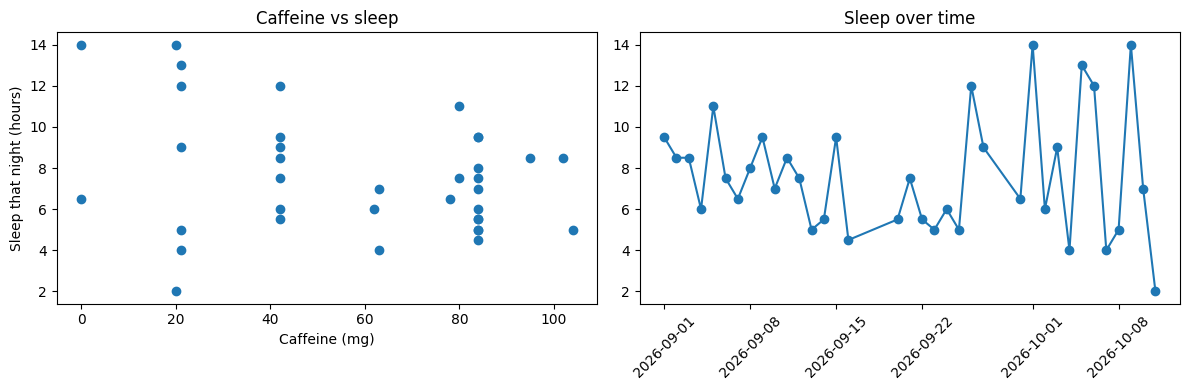

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].scatter(df["caffeine_mg"], df["sleep_hours"])
ax[0].set_xlabel("Caffeine (mg)")
ax[0].set_ylabel("Sleep that night (hours)")
ax[0].set_title("Caffeine vs sleep")

ax[1].plot(df["date"], df["sleep_hours"], marker="o")
ax[1].set_title("Sleep over time")
ax[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [11]:
print(df[["caffeine_mg", "sleep_hours", "exam_season"]].corr())

print("\nAverage by exam season (1 = exams):")
print(df.groupby("exam_season")[["caffeine_mg", "sleep_hours"]].mean())

             caffeine_mg  sleep_hours  exam_season
caffeine_mg     1.000000    -0.289237     0.467933
sleep_hours    -0.289237     1.000000    -0.143533
exam_season     0.467933    -0.143533     1.000000

Average by exam season (1 = exams):
             caffeine_mg  sleep_hours
exam_season                          
0.0            47.478261     7.934783
1.0            76.769231     7.076923


In [12]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_predict, LeaveOneOut
from sklearn.metrics import mean_absolute_error

X = df[["caffeine_mg", "exam_season"]]
y = df["sleep_hours"]

pred = cross_val_predict(LinearRegression(), X, y, cv=LeaveOneOut())
print("Model error:   ", round(mean_absolute_error(y, pred), 2), "hours")
print("Baseline error:", round(mean_absolute_error(y, [y.mean()] * len(y)), 2), "hours")

Model error:    2.44 hours
Baseline error: 2.31 hours


In [13]:
print(df.sort_values("date").tail(3))

         date  caffeine_mg  sleep_hours  exam_season wake_time
38 2026-10-09         20.0         14.0          0.0      4:20
39 2026-10-10         63.0          7.0          0.0     13:13
40 2026-10-11         20.0          2.0          0.0     14:00


In [14]:
df["period"] = df["exam_season"].map({0: "non-exam", 1: "exam"})
print(df.groupby("period")["sleep_hours"].agg(["mean", "median", "min", "max", "count"]))

              mean  median  min   max  count
period                                      
exam      7.076923     7.5  4.5   9.5     13
non-exam  7.934783     7.0  2.0  14.0     23


In [15]:
exam = df[df.exam_season == 1]
print(exam["date"].min(), exam["date"].max())

2026-09-06 00:00:00 2026-09-21 00:00:00


In [16]:
df["wake_hours"] = (pd.to_datetime(df["wake_time"], format="%H:%M").dt.hour
                    + pd.to_datetime(df["wake_time"], format="%H:%M").dt.minute / 60)

w = df.dropna(subset=["wake_hours"])
print(len(w), "days with wake time")
print(w[["date", "wake_hours", "sleep_hours"]])
print(w[["wake_hours", "sleep_hours"]].corr())

12 days with wake time
         date  wake_hours  sleep_hours
29 2026-09-30   10.516667          6.5
30 2026-10-01    4.500000         14.0
31 2026-10-02   12.500000          6.0
32 2026-10-03   10.500000          9.0
33 2026-10-04   13.000000          4.0
34 2026-10-05    6.000000         13.0
35 2026-10-06   13.000000         12.0
36 2026-10-07   12.683333          4.0
37 2026-10-08    6.450000          5.0
38 2026-10-09    4.333333         14.0
39 2026-10-10   13.216667          7.0
40 2026-10-11   14.000000          2.0
             wake_hours  sleep_hours
wake_hours     1.000000    -0.695383
sleep_hours   -0.695383     1.000000


In [17]:
df = df.sort_values("date").reset_index(drop=True)
df["wake_next"] = df["wake_hours"].shift(-1)
consecutive = (df["date"].shift(-1) - df["date"]) == pd.Timedelta(days=1)
df.loc[~consecutive, "wake_next"] = None
df["bed_hours"] = (df["wake_next"] - df["sleep_hours"]) % 24

w = df.dropna(subset=["wake_next"])
print(w[["date", "sleep_hours", "wake_next", "bed_hours"]])
print(w[["wake_next", "sleep_hours"]].corr())

         date  sleep_hours  wake_next  bed_hours
24 2026-09-30          6.5   4.500000  22.000000
25 2026-10-01         14.0  12.500000  22.500000
26 2026-10-02          6.0  10.500000   4.500000
27 2026-10-03          9.0  13.000000   4.000000
28 2026-10-04          4.0   6.000000   2.000000
29 2026-10-05         13.0  13.000000   0.000000
30 2026-10-06         12.0  12.683333   0.683333
31 2026-10-07          4.0   6.450000   2.450000
32 2026-10-08          5.0   4.333333  23.333333
33 2026-10-09         14.0  13.216667  23.216667
34 2026-10-10          7.0  14.000000   7.000000
             wake_next  sleep_hours
wake_next     1.000000     0.737943
sleep_hours   0.737943     1.000000
